# 11 · Second attempt: GLiNER2.5 and time-aware label priors

Notebook 10's stacks were scored on the test sets on 9 November 2026. This adds two things to them, found after that run:

- **GLiNER2.5** (Fastino, Apache 2.0), a small encoder that reads a text and every label's name together and scores
  each label in one pass. It is fine-tuned on each test set's training data: `GLiNER2.5-multi-Decide` on HumSet, whose
  excerpts are in English, French and Spanish, and `GLiNER2.5-Decide` on MultiEURLEX's English laws, where it scores
  each law's candidate list, as the reranker does.
- **Time-aware label priors**, for MultiEURLEX only, since HumSet's excerpts carry no dates. For each candidate label the
  combiner is also given its count in the 5,000 most recent training documents, that share against its overall share,
  and the years since it was last used. On development laws, recent use predicted later use better than overall use
  (rank correlation 0.58 against 0.52), and a label's recent trend tended to continue (0.45). No prior work using such
  priors in subject indexing or large-label classification was found; the nearest is tag recommendation for
  individual users.

## The bar, written on 10 November 2026, before GLiNER2.5 was fine-tuned or the priors were scored

**This is a second attempt.** Both test sets were scored once in notebook 10, so these results are reported as a second
attempt made after seeing the first, never as a clean first result. Everything below is still chosen on development
data, and the test sets are scored once more, whatever that shows.

**What is added.** Starting from notebook 10's chosen stacks, each addition is tried on the same development items. It
is kept only if it raises the development score by more than the same margin as before: 0.001 of mean macro F1 on
HumSet, and 0.1 points of mean R-Precision on MultiEURLEX.

**The pass marks are notebook 10's, unchanged:** on HumSet the 95% interval above HumBERT's printed score in every
category (0.78, 0.70, 0.54, 0.71 and 0.51), and on MultiEURLEX above BERT's 48.4 on all labels and 67.7 at level 3.
"Well ahead" still means more than 5 points of mean R-Precision, or 0.05 of mean macro F1.

**Also reported, pass or fail:** the second attempt's gain over the first on the same test items, with an interval;
GLiNER2.5's own scores, with and without fine-tuning; whether each addition was kept, and its development gain; what
the combiner relies on; and the fine-tuning cost.

These bars do not change after seeing results.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image

from tiered_taxonomy import benchmarks as bm
from tiered_taxonomy import experiment as ex
from tiered_taxonomy import figures as fg
from tiered_taxonomy import gpu_jobs as gj
from tiered_taxonomy import new_technique as nt
from tiered_taxonomy import signals as sg
from tiered_taxonomy.config import FIGURES, data_root, load_config
from tiered_taxonomy.methods import combined as cb

root = data_root()
config = load_config()
seed = config["seed"]
words = config["text"]["input_words"]
settings = cb.CombinedSettings(per_source=config["combined"]["per_source"], seed=seed)
plan = config["new_technique"]
jobs = ex.load_results("gpu_jobs")
recent = config["second_attempt"]["recent_documents"]
humset = ex.load_humset(root)
eurlex = ex.load_eurlex(root)
first = ex.load_results("10_combined_method")
results = {}
pd.DataFrame({run: jobs["runs"][run] for run in ("gliner_humset", "gliner_eurlex_newer")}).T[
    ["base", "flavor", "hours"]
]

/Users/matthewharris/git/nvidia-autoontology-demo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,base,flavor,hours
gliner_humset,fastino/GLiNER2.5-multi-Decide,a10g-small,2.7
gliner_eurlex_newer,fastino/GLiNER2.5-Decide,a10g-small,2.46


## Getting GLiNER2.5's rankings

The runs were launched with `scripts/gpu_jobs.py`. Each scored the development items before
fine-tuning too, which is shown here, by mean R-Precision on the items that chose nothing.

In [2]:
for run, folder in (("gliner_humset", "humset"), ("gliner_eurlex_newer", "eurlex_newer")):
    data = humset if folder == "humset" else eurlex
    dropped = nt.fetch_fine_tuned(root, folder, run, "gliner", data.taxonomy)
    print(run, "labels dropped for having no place in the tree:", len(dropped))
results["gliner_history"] = {
    run: nt.fetch_history(root, run) for run in ("gliner_humset", "gliner_eurlex_newer")
}
pd.DataFrame(
    {
        run: {entry["stage"]: entry["development_mrp"] for entry in history}
        for run, history in results["gliner_history"].items()
    }
)

gliner_humset labels dropped for having no place in the tree: 0


gliner_eurlex_newer labels dropped for having no place in the tree: 0


,gliner_humset,gliner_eurlex_newer
without fine-tuning,31.680,8.933
fine-tuned,66.507,53.448


## Choosing what to add, on development items only

The same development items as notebook 10: on HumSet the combiner trains on 6,000 excerpts, and of the other 4,000 half
choose thresholds and half are scored; on MultiEURLEX it trains on the first 2,000 later development laws and is scored
on the next 500.

In [3]:
def show_addition(test_set, choice):
    """Return the development score of the first attempt and of each addition, and print what was kept."""
    before = nt.headline(test_set, choice["variants"]["first attempt"])
    table = pd.DataFrame(
        {
            "development score": {
                name: nt.headline(test_set, scores) for name, scores in choice["variants"].items()
            },
        }
    )
    table["gain"] = table["development score"] - before
    with_them = nt.headline(test_set, choice["chosen_scores"])
    print(f"Kept: {', '.join(choice['kept']) or 'nothing'}. With them: {with_them:.4f}.")
    return table.round(4)


def kept(choice):
    return {key: choice[key] for key in ("variants", "kept", "names", "priors", "chosen_scores", "single")}


def dated(items):
    return sorted(((bm.law_year(item.id), sorted(item.labels)) for item in items), key=lambda pair: pair[0])


order = np.random.default_rng(seed).permutation(len(humset.dev))
drawn = nt.with_all_tiers(
    [humset.dev[int(i)] for i in order[: plan["humset"]["fit_items"] + plan["humset"]["cut_items"]]]
)
h_fit, h_cut = drawn[: plan["humset"]["fit_items"]], drawn[plan["humset"]["fit_items"] :]
half = len(h_cut) // 2
h_base = first["humset"]["sources"]
h_dev = nt.expand_sources(sg.load_sources(root, humset.name, [*h_base, "gliner"], "dev"))
h_graph = cb.LabelGraph(humset.taxonomy, [sorted(bm.gold_with_parents(item)) for item in humset.train])
h_choice = nt.addition_choice(
    "humset",
    h_fit,
    h_cut,
    h_cut[:half],
    h_cut[half:],
    h_dev,
    h_base,
    (h_graph, None),
    words,
    settings,
    humset.taxonomy,
)
results["humset_choice"] = kept(h_choice)
show_addition("humset", h_choice)

Kept: nothing. With them: 0.5770.


,development score,gain
first attempt,0.5770,0.0000
+ gliner,0.5771,0.0002


In [4]:
early, late = bm.split_by_date(eurlex.dev)
late = late[: plan["eurlex"]["fit_items"] + plan["eurlex"]["cut_items"]]
e_fit, e_cut = late[: plan["eurlex"]["fit_items"]], late[plan["eurlex"]["fit_items"] :]
e_base = first["eurlex"]["sources"]
e_dev = nt.eurlex_sources(root, [*e_base, "gliner"], "dev", with_newer=True)
newer_documents = [sorted(item.labels) for item in [*eurlex.train, *early]]
newer_graph = cb.LabelGraph(eurlex.taxonomy, newer_documents)
newer_timed = cb.LabelGraph(
    eurlex.taxonomy,
    newer_documents,
    priors=cb.TimedPriors.from_documents(dated([*eurlex.train, *early]), recent),
)
e_choice = nt.addition_choice(
    "eurlex",
    e_fit,
    e_cut,
    e_fit,
    e_cut,
    e_dev,
    e_base,
    (newer_graph, newer_timed),
    words,
    settings,
    eurlex.taxonomy,
)
results["eurlex_choice"] = kept(e_choice)
show_addition("eurlex", e_choice)

Kept: gliner, time-aware priors. With them: 71.7392.


,development score,gain
first attempt,70.9654,0.0000
+ gliner,71.2877,0.3222
+ time-aware priors,71.4353,0.4698


In [5]:
t_base = first["eurlex_train_only"]["sources"]
t_dev = nt.eurlex_sources(root, t_base, "dev", with_newer=False)
train_documents = [sorted(item.labels) for item in eurlex.train]
train_graph = cb.LabelGraph(eurlex.taxonomy, train_documents)
train_timed = cb.LabelGraph(
    eurlex.taxonomy, train_documents, priors=cb.TimedPriors.from_documents(dated(eurlex.train), recent)
)
t_choice = nt.addition_choice(
    "eurlex",
    e_fit,
    e_cut,
    e_fit,
    e_cut,
    t_dev,
    t_base,
    (train_graph, train_timed),
    words,
    settings,
    eurlex.taxonomy,
)
results["eurlex_train_only_choice"] = kept(t_choice)
show_addition("eurlex", t_choice)

Kept: time-aware priors. With them: 69.1781.


,development score,gain
first attempt,67.3707,0.0000
+ time-aware priors,69.1781,1.8075


## GLiNER2.5 on its own, on development items

Each source's own score on the same development items as above, best first.

In [6]:
own = {
    "HumSet, mean macro F1": {name: nt.headline("humset", s) for name, s in h_choice["single"].items()},
    "MultiEURLEX, mean R-Precision": {
        name: nt.headline("eurlex", s) for name, s in e_choice["single"].items()
    },
}
pd.DataFrame(own).rename(index=fg.method_name).sort_values(
    "MultiEURLEX, mean R-Precision", ascending=False
).round(4)

,"HumSet, mean macro F1","MultiEURLEX, mean R-Precision"
Fine-tuned encoder,0.5660,56.0648
Fine-tuned small LLM,NaN,55.3179
"GLiNER2.5, fine-tuned",0.5114,53.6644
Similar documents,NaN,50.2740
Fine-tuned reranker,NaN,49.0677
Label search,0.2278,11.4936
XR-Transformer (paper),0.5469,NaN


## The second test run

The additions are now fixed. Each test set is scored once more. The first attempt's stack is rebuilt beside it, on the
same development items, so the gain is measured on the same test items with a paired interval.

In [7]:
h_test = nt.with_all_tiers(humset.test)
if len(h_test) != 15147:
    raise ValueError(f"expected all 15,147 HumSet test excerpts, found {len(h_test)}")
h_names = h_choice["names"]
h_best = first["humset"]["best_single_source"]
h_test_sources = nt.expand_sources(
    sg.load_sources(root, humset.name, sorted({*h_names, *h_base, h_best}), "test")
)
h_stack = nt.Stack(h_names, h_fit, h_cut, h_dev, h_test_sources, h_choice["graph"], words, settings)
h_first = nt.Stack(h_base, h_fit, h_cut, h_dev, h_test_sources, h_graph, words, settings)
h_final = nt.humset_final(h_stack, h_test, h_best, humset.taxonomy, seed)
sg.save_signal(
    root,
    humset.name,
    "second_attempt",
    "test",
    {item.id: ranking for item, ranking in zip(h_test, h_final.pop("rankings"), strict=True)},
)
h_against = nt.humset_against(h_stack, h_first, h_test, humset.taxonomy, seed)
results["humset"] = {**h_final, "sources": h_names, "best_single_source": h_best, "against_first": h_against}
categories = [*bm.HUMBERT_BEST, "Mean"]
printed = {**bm.HUMBERT_BEST, "Mean": float(np.mean(list(bm.HUMBERT_BEST.values())))}
point, low, high = h_against["gain"]
print(f"Second attempt over first: {point:+.4f} mean macro F1 (95% {low:+.4f} to {high:+.4f})")
pd.DataFrame(
    {
        "HumBERT, printed": printed,
        "first attempt": h_against["first"],
        "second attempt": h_final["scores"],
        "95% low": {c: v[0] for c, v in h_final["intervals"].items()},
        "95% high": {c: v[1] for c, v in h_final["intervals"].items()},
        "passes": {**h_final["passes"], "Mean": all(h_final["passes"].values())},
    }
).loc[categories].round(3)

Second attempt over first: +0.0000 mean macro F1 (95% +0.0000 to +0.0000)


,"HumBERT, printed",first attempt,second attempt,95% low,95% high,passes
Sectors,0.780,0.742,0.742,0.735,0.750,False
Pillars 1D,0.700,0.553,0.553,0.535,0.568,False
Subpillars 1D,0.540,0.453,0.453,0.438,0.464,False
Pillars 2D,0.710,0.646,0.646,0.635,0.656,False
Subpillars 2D,0.510,0.475,0.475,0.463,0.488,False
Mean,0.648,0.574,0.574,0.567,0.579,False


In [8]:
e_test = eurlex.test
if len(e_test) != 5000:
    raise ValueError(f"expected all 5,000 MultiEURLEX test laws, found {len(e_test)}")


def eurlex_run(choice, base, dev_sources, graph, base_graph, with_newer, counts, name):
    best = nt.best_single("eurlex", {"single": choice["single"]})
    names = choice["names"]
    test_sources = nt.eurlex_sources(root, sorted({*names, *base, best}), "test", with_newer=with_newer)
    stack = nt.Stack(names, e_fit, e_cut, dev_sources, test_sources, graph, words, settings)
    previous = nt.Stack(base, e_fit, e_cut, dev_sources, test_sources, base_graph, words, settings)
    final = nt.eurlex_final(stack, e_test, best, eurlex.taxonomy, counts, seed)
    sg.save_signal(
        root,
        eurlex.name,
        name,
        "test",
        {item.id: ranking for item, ranking in zip(e_test, final.pop("rankings"), strict=True)},
    )
    against = nt.eurlex_against(stack, previous, e_test, eurlex.taxonomy, seed)
    return {
        **final,
        "sources": names,
        "priors": choice["priors"],
        "best_single_source": best,
        "against_first": against,
    }


newer_counts = newer_graph.counts
results["eurlex"] = eurlex_run(
    e_choice, e_base, e_dev, e_choice["graph"], newer_graph, True, newer_counts, "second_attempt"
)
results["eurlex_train_only"] = eurlex_run(
    t_choice,
    t_base,
    t_dev,
    t_choice["graph"],
    train_graph,
    False,
    eurlex.train_counts,
    "second_attempt_train_only",
)
rows = {"BERT, printed": bm.MULTI_EURLEX_BERT}
for key, label in (("eurlex", "with newer laws"), ("eurlex_train_only", "training laws only")):
    run = results[key]
    rows[f"first attempt, {label}"] = run["against_first"]["first"]
    rows[f"second attempt, {label}"] = run["scores"]
    rows[f"  95% interval, {label}"] = {
        level: f"{low:.1f} to {high:.1f}" for level, (low, high) in run["intervals"].items()
    }
    rows[f"  gain over first attempt, {label}"] = {
        level: f"{p:+.2f} ({lo:+.2f} to {hi:+.2f})"
        for level, (p, lo, hi) in run["against_first"]["gain"].items()
    }
    rows[f"  passes, {label}"] = run["passes"]
    rows[f"  well ahead (interval above BERT + 5), {label}"] = run["well_ahead"]
pd.DataFrame(rows).T.rename(columns={"all": "all labels", "level_3": "level 3"})

,all labels,level 3
"BERT, printed",48.4,67.7
"first attempt, with newer laws",62.417752,74.489808
"second attempt, with newer laws",63.963705,75.49525
"95% interval, with newer laws",63.4 to 64.5,74.9 to 76.1
"gain over first attempt, with newer laws",+1.55 (+1.25 to +1.79),+1.01 (+0.73 to +1.28)
"passes, with newer laws",True,True
"well ahead (interval above BERT + 5), with newer laws",True,True
"first attempt, training laws only",60.037853,72.897517
"second attempt, training laws only",61.04827,73.637156
"95% interval, training laws only",60.3 to 61.7,73.0 to 74.2


## What the combiner relies on

How much its ranking of candidates on the held-out development items falls when one signal is shuffled, measured by
average precision. The ten largest per stack.

In [9]:
importance = pd.DataFrame(
    {key: results[key]["importance"] for key in ("humset", "eurlex", "eurlex_train_only")}
)
pd.concat(
    [
        importance[key]
        .sort_values(ascending=False)
        .head(10)
        .round(4)
        .reset_index()
        .set_axis(["signal", "drop"], axis=1)
        for key in importance
    ],
    axis=1,
    keys=importance.columns,
)

humset                      eurlex          \
                 signal    drop              signal    drop   
0      classifier_score  0.5745    classifier_score  0.1925   
1  xr_transformer_score  0.0602        parent_score  0.0838   
2    log_training_count  0.0027  log_training_count  0.0700   
3         co_occurrence  0.0016    log_recent_count  0.0471   
4          parent_score  0.0001           llm_score  0.0442   
5                  tier  0.0001      reranker_score  0.0352   
6          name_in_text  0.0000        gliner_score  0.0324   
7    label_search_score  0.0000       co_occurrence  0.0300   
8      classifier_found  0.0000    sources_agreeing  0.0270   
9    label_search_found  0.0000         child_score  0.0264   

            eurlex_train_only          
                       signal    drop  
0            classifier_score  0.2743  
1          log_training_count  0.0578  
2            log_recent_count  0.0522  
3                parent_score  0.0464  
4        xr_transformer_score  0.0339  
5            years_since_used  0.0276  
6                 child_score  0.0254  
7                recent_trend  0.0227  
8  embedding_classifier_score  0.0209  
9            sources_agreeing  0.0203

## What it cost

GPU time on Hugging Face Jobs for the two GLiNER2.5 runs, from their job records. The priors cost nothing to compute.

In [10]:
def job_cost(run):
    return gj.run_cost(jobs, run)


results["gliner_cost_usd"] = {
    run: round(job_cost(run), 2) for run in ("gliner_humset", "gliner_eurlex_newer")
}
results["all_jobs_cost_usd"] = round(sum(job_cost(run) for run in jobs["runs"]), 2)
print(
    "GLiNER2.5 runs: $",
    results["gliner_cost_usd"],
    "| every fine-tuning job so far: $",
    results["all_jobs_cost_usd"],
)

GLiNER2.5 runs: $ {'gliner_humset': 2.7, 'gliner_eurlex_newer': 2.46} | every fine-tuning job so far: $ 23.15


## Charts

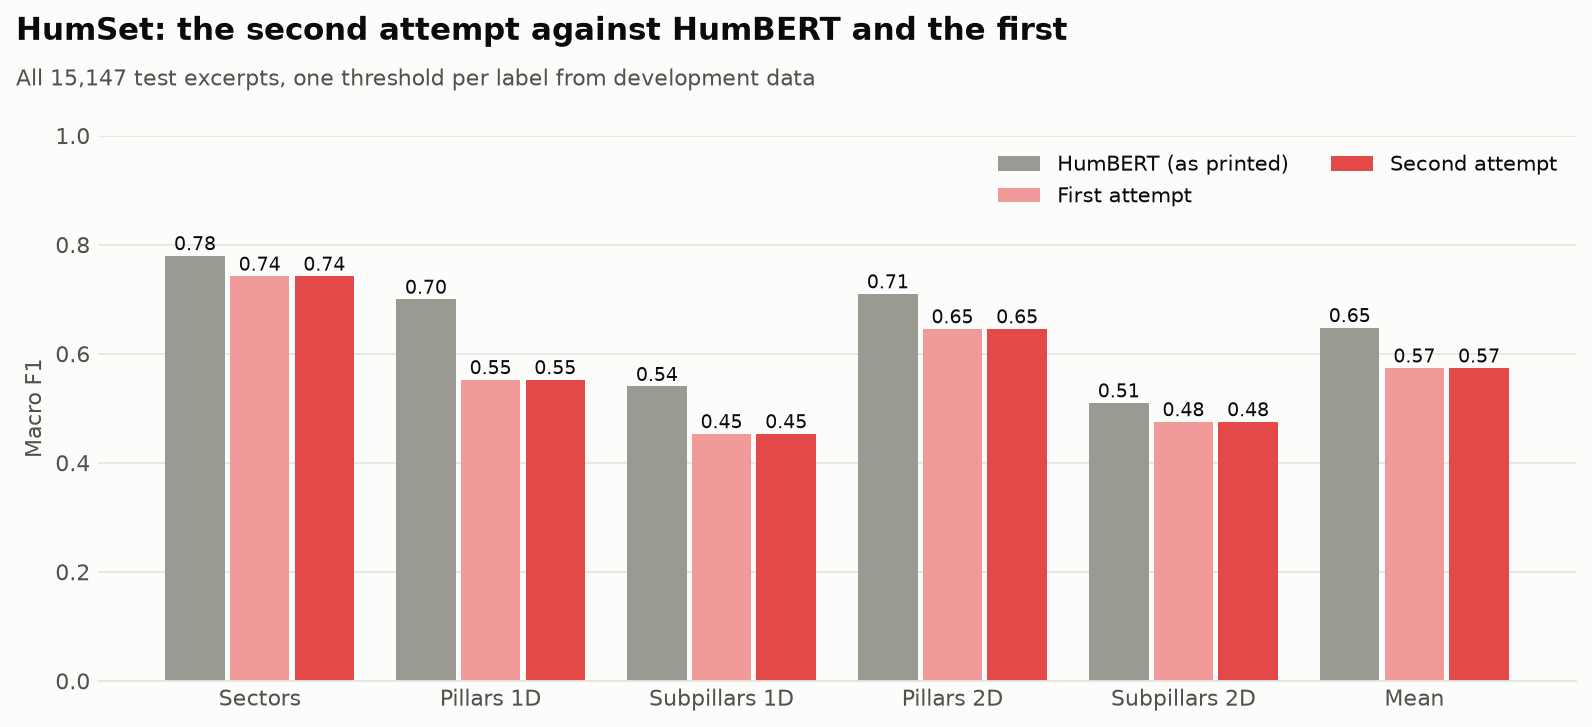

In [11]:
series = {
    "humbert_printed": printed,
    "first_attempt": h_against["first"],
    "second_attempt": results["humset"]["scores"],
}
path = fg.category_bars(
    {name: {category: values[category] for category in categories} for name, values in series.items()},
    "Macro F1",
    "HumSet: the second attempt against HumBERT and the first",
    "All 15,147 test excerpts, one threshold per label from development data",
    FIGURES / "11_humset.png",
)
Image(str(path), width=900)

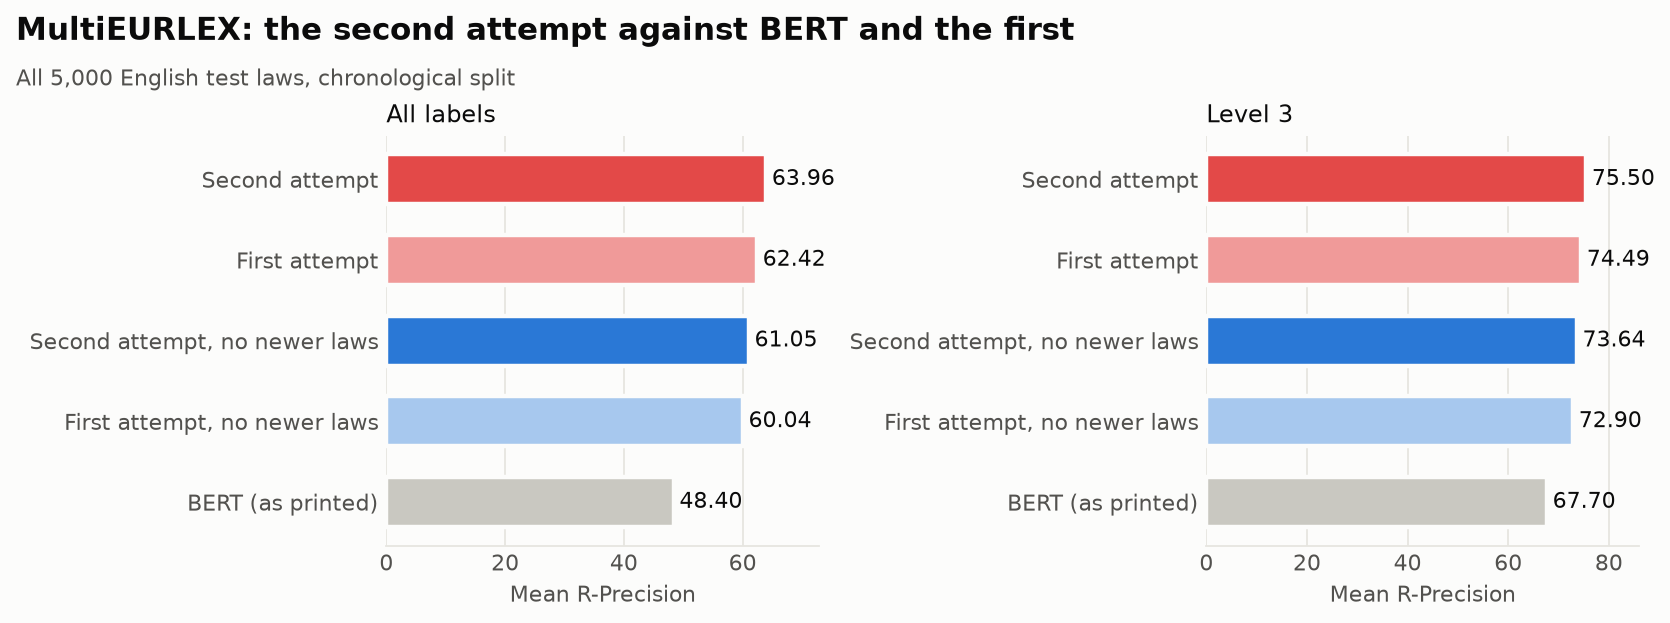

In [12]:
def eurlex_panel(level):
    return {
        "bert_printed": bm.MULTI_EURLEX_BERT[level],
        "first_attempt": results["eurlex"]["against_first"]["first"][level],
        "second_attempt": results["eurlex"]["scores"][level],
        "first_attempt_train_only": results["eurlex_train_only"]["against_first"]["first"][level],
        "second_attempt_train_only": results["eurlex_train_only"]["scores"][level],
    }


path = fg.method_bars(
    {"All labels": eurlex_panel("all"), "Level 3": eurlex_panel("level_3")},
    "Mean R-Precision",
    "MultiEURLEX: the second attempt against BERT and the first",
    "All 5,000 English test laws, chronological split",
    FIGURES / "11_eurlex.png",
)
Image(str(path), width=900)

In [13]:
ex.save_results("11_second_attempt", results)
print("saved")

saved
